In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FINAL_DIR = PROJECT_ROOT / "data" / "final"
TABLES_DIR = PROJECT_ROOT / "tables"

TABLES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    FINAL_DIR / "model_features_20d_provisional.csv",
    parse_dates=["Date"]
)

df = df.sort_values("Date").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

assert len(df) == 3944

print("Dataset loaded successfully!")

Dataset shape: (3944, 17)
Date range: 2010-03-31 00:00:00 to 2025-12-02 00:00:00
Dataset loaded successfully!


In [2]:
MARKET_FEATURES = [
    "Return_Lag1",
    "Absolute_Return",
    "RV_Historical_5D",
    "RV_Historical_10D",
    "RV_Historical_20D",
    "RV_Historical_60D",
    "RV_20D_Lag1"
]

GPR_FEATURES = [
    "GPR_Level",
    "GPR_Change",
    "GPR_MA5",
    "GPR_MA20"
]

EPU_FEATURES = [
    "EPU_Level",
    "EPU_Change",
    "EPU_MA5",
    "EPU_MA20"
]

FEATURE_SETS = {
    "A_Baseline": MARKET_FEATURES,
    "B_GPR": MARKET_FEATURES + GPR_FEATURES,
    "C_EPU": MARKET_FEATURES + EPU_FEATURES,
    "D_Combined": (
        MARKET_FEATURES + GPR_FEATURES + EPU_FEATURES
    )
}

TARGET = "RV_Future_20D"

for experiment, features in FEATURE_SETS.items():
    print(f"{experiment}: {len(features)} predictors")

A_Baseline: 7 predictors
B_GPR: 11 predictors
C_EPU: 11 predictors
D_Combined: 15 predictors


In [3]:
HORIZON = 20

validation_start = pd.Timestamp("2020-01-01")

first_validation_position = df.index[
    df["Date"] >= validation_start
][0]

last_train_position = (
    first_validation_position - HORIZON - 1
)

train = df.iloc[
    :last_train_position + 1
].copy()

validation = df[
    (df["Date"] >= "2020-01-01") &
    (df["Date"] < "2023-01-01")
].copy()

print("Training observations:", len(train))
print("Validation observations:", len(validation))

print("Last training date:", train["Date"].max())
print("First validation date:", validation["Date"].min())

assert len(train) == 2436
assert len(validation) == 756

assert (
    train.index.max() + HORIZON
    < validation.index.min()
)

print("Chronological split and purge checks passed!")

Training observations: 2436
Validation observations: 756
Last training date: 2019-12-02 00:00:00
First validation date: 2020-01-02 00:00:00
Chronological split and purge checks passed!


In [4]:
def evaluate_forecast(y_true, y_pred):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(
        y_true, y_pred
    )

    epsilon = 1e-4

    safe_mape = np.mean(
        np.abs(y_true - y_pred) /
        np.maximum(np.abs(y_true), epsilon)
    ) * 100

    return {
        "RMSE": rmse,
        "MAE": mae,
        "Safe_MAPE": safe_mape
    }

In [ ]:
xgb_results = []

xgb_models = {}

xgb_predictions_by_set = {}

for experiment, features in FEATURE_SETS.items():

    print(f"\nTraining: {experiment}")

    X_train = train[features]
    y_train = train[TARGET]

    X_validation = validation[features]
    y_validation = validation[TARGET]

    model = XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_validation)

    predictions = np.maximum(predictions, 0)

    metrics = evaluate_forecast(
        y_validation,
        predictions
    )

    xgb_results.append({
        "Experiment": experiment,
        "Predictors": len(features),
        **metrics
    })

    xgb_models[experiment] = model

    xgb_predictions_by_set[experiment] = predictions

xgb_results_df = pd.DataFrame(xgb_results)

xgb_results_df = xgb_results_df.sort_values(
        "RMSE"
).reset_index(drop=True)

print("=" * 60)
print("XGBOOST FEATURE ABLATION RESULTS")
print("=" * 60)

display(xgb_results_df.round(6))

xgb_results_df.to_csv(
    TABLES_DIR / "xgboost_feature_ablation_provisional.csv",
    index=False
)

print("\nXGBoost results saved successfully!")


Training: A_Baseline

Training: B_GPR

Training: C_EPU

Training: D_Combined
XGBOOST FEATURE ABLATION RESULTS


,Experiment,Predictors,RMSE,MAE,Safe_MAPE
0,B_GPR,11,0.037366,0.019736,29.216081
1,A_Baseline,7,0.037992,0.019562,27.495317
2,D_Combined,15,0.040302,0.022721,34.974955
3,C_EPU,11,0.040492,0.021972,33.263930



XGBoost results saved successfully!


In [7]:
comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "RMSE": 0.035895,
        "MAE": 0.018616,
        "Safe_MAPE": 27.730350
    },
    {
        "Model": "Random Forest",
        "RMSE": 0.038677,
        "MAE": 0.019927,
        "Safe_MAPE": 27.855195
    },
    {
        "Model": "Persistence",
        "RMSE": 0.043013,
        "MAE": 0.023945,
        "Safe_MAPE": 37.751981
    },
    {
        "Model": "XGBoost",
        **evaluate_forecast(
            validation[TARGET],
            xgb_predictions_by_set["A_Baseline"]
        )
    }
])

comparison = comparison.sort_values(
    "RMSE"
).reset_index(drop=True)

display(comparison.round(6))

comparison.to_csv(
    TABLES_DIR / "xgboost_baseline_comparison.csv",
    index=False
)

,Model,RMSE,MAE,Safe_MAPE
0,Linear Regression,0.035895,0.018616,27.730350
1,XGBoost,0.037992,0.019562,27.495317
2,Random Forest,0.038677,0.019927,27.855195
3,Persistence,0.043013,0.023945,37.751981


In [8]:
combined_model = xgb_models["D_Combined"]

importance_df = pd.DataFrame({
    "Feature": FEATURE_SETS["D_Combined"],
    "Importance": combined_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("XGBOOST FEATURE IMPORTANCE")
print("=" * 60)

display(importance_df)

importance_df.to_csv(
    TABLES_DIR / "xgboost_feature_importance_provisional.csv",
    index=False
)

XGBOOST FEATURE IMPORTANCE


,Feature,Importance
0,RV_Historical_10D,0.218708
1,RV_Historical_5D,0.149819
2,RV_Historical_20D,0.142075
3,GPR_MA20,0.066999
4,RV_Historical_60D,0.057363
5,EPU_MA20,0.055913
6,RV_20D_Lag1,0.053097
7,Return_Lag1,0.051579
8,EPU_MA5,0.051139
9,EPU_Level,0.038753


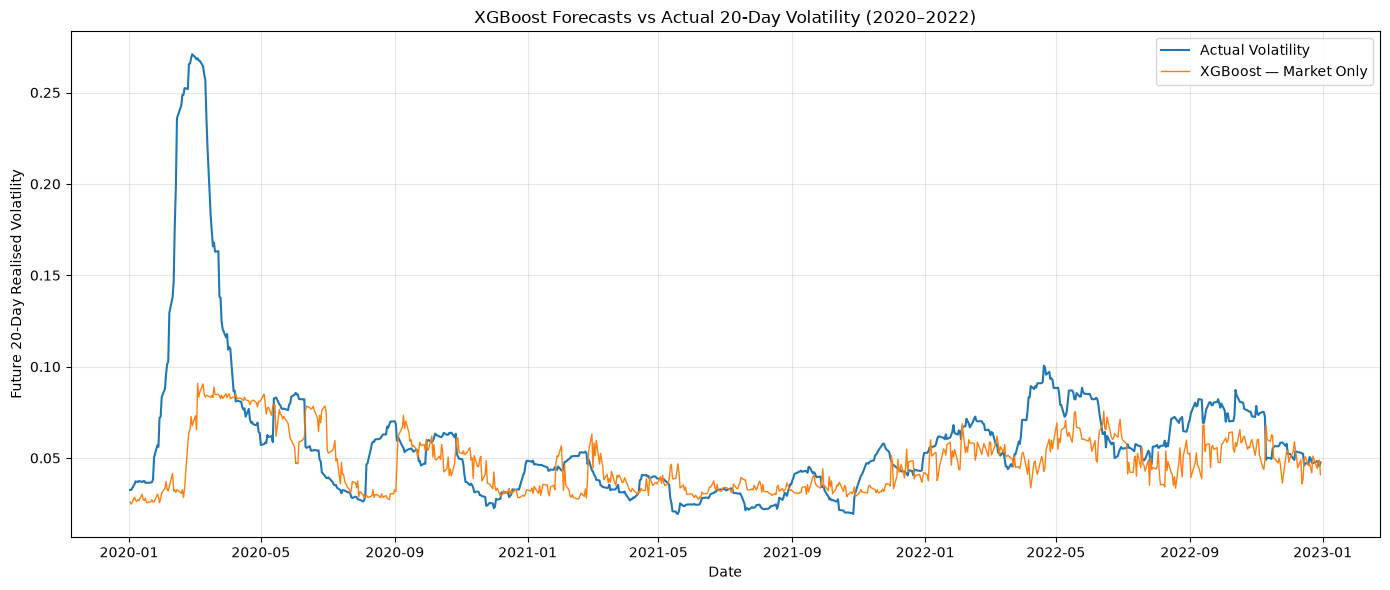

In [9]:
import matplotlib.pyplot as plt

FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(14, 6))

plt.plot(
    validation["Date"],
    validation[TARGET],
    label="Actual Volatility",
    linewidth=1.5
)

plt.plot(
    validation["Date"],
    xgb_predictions_by_set["A_Baseline"],
    label="XGBoost — Market Only",
    linewidth=1
)

plt.title(
    "XGBoost Forecasts vs Actual 20-Day Volatility (2020–2022)"
)

plt.xlabel("Date")
plt.ylabel("Future 20-Day Realised Volatility")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "xgboost_validation_forecasts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()